# Data Visualization with Matplotlib and Seaborn
**GDG on Campus | COMSATS University, Attock Campus: AI/ML Team, Month 2, Week 1**

Author: `<your-github-username>`

This notebook contains all 14 tasks (7 Matplotlib + 7 Seaborn). Each plot is followed by a short written insight.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
plt.rcParams["figure.dpi"] = 100

tips    = sns.load_dataset("tips")
flights = sns.load_dataset("flights")
mpg     = sns.load_dataset("mpg")
penguins = sns.load_dataset("penguins")
titanic = sns.load_dataset("titanic")

# Part 1: Matplotlib Tasks

## Task 1: Line plot (flights)

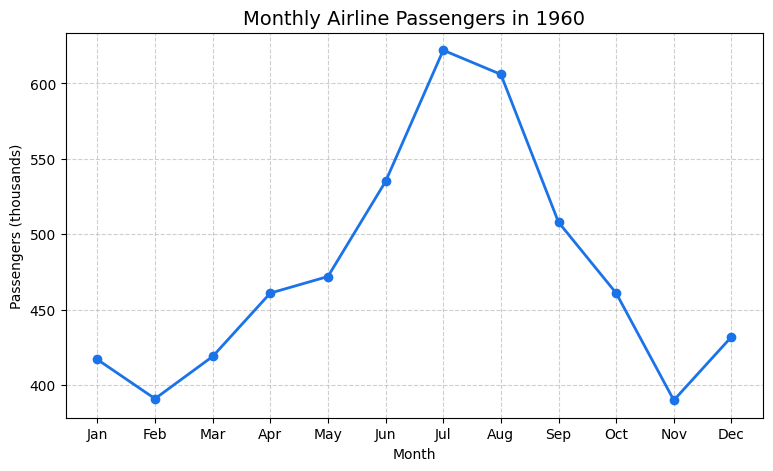

In [2]:
f1960 = flights[flights["year"] == 1960]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(f1960["month"].astype(str), f1960["passengers"], marker="o", color="#1a73e8", linewidth=2)
ax.set_title("Monthly Airline Passengers in 1960", fontsize=14)
ax.set_xlabel("Month")
ax.set_ylabel("Passengers (thousands)")
ax.grid(True, linestyle="--", alpha=0.6)
plt.show()

**Insight:** Passenger numbers climb from about 417 in January to a peak of 622 in July, then fall back to roughly 390 by November. The pronounced summer peak shows strong seasonality, with travel demand highest in the holiday months.

## Task 2: Bar chart (tips)

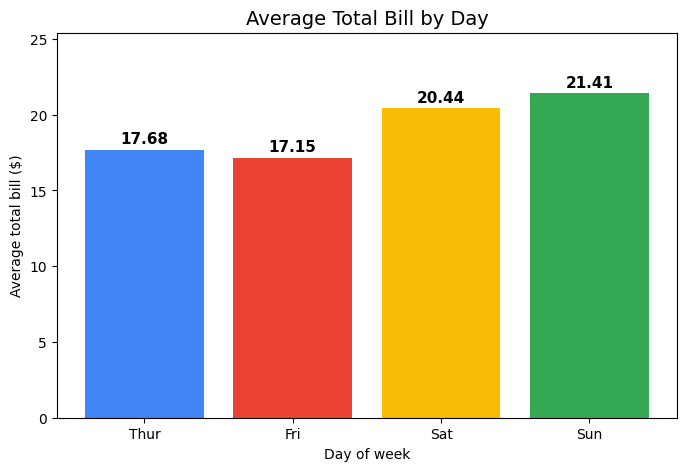

In [3]:
avg_day = tips.groupby("day", observed=True)["total_bill"].mean()
colors = ["#4285F4", "#EA4335", "#FBBC05", "#34A853"]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(avg_day.index.astype(str), avg_day.values, color=colors)
for b in bars:
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.2, f"{b.get_height():.2f}",
            ha="center", va="bottom", fontsize=11, fontweight="bold")
ax.set_title("Average Total Bill by Day", fontsize=14)
ax.set_xlabel("Day of week")
ax.set_ylabel("Average total bill ($)")
ax.set_ylim(0, avg_day.max() + 4)
plt.show()

**Insight:** Weekend bills are higher: Sunday averages about \$21.41 and Saturday \$20.44, versus roughly \$17 on Thursday and Friday. Weekend dining likely involves larger groups or bigger orders.

## Task 3: Horizontal bar chart (mpg)

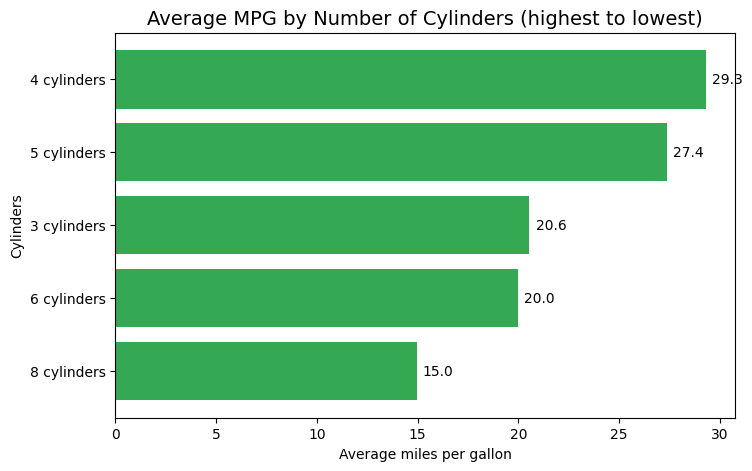

In [4]:
avg_cyl = mpg.groupby("cylinders")["mpg"].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
y_labels = [f"{c} cylinders" for c in avg_cyl.index]
ax.barh(y_labels, avg_cyl.values, color="#34A853")
ax.invert_yaxis()  # highest at the top
for i, v in enumerate(avg_cyl.values):
    ax.text(v + 0.3, i, f"{v:.1f}", va="center")
ax.set_title("Average MPG by Number of Cylinders (highest to lowest)", fontsize=14)
ax.set_xlabel("Average miles per gallon")
ax.set_ylabel("Cylinders")
plt.show()

**Insight:** 4-cylinder cars are the most efficient at about 29.3 mpg, while 8-cylinder cars manage only about 15 mpg. Fuel economy generally falls as engine size grows. The 3-cylinder group has few cars, so its value is less reliable.

## Task 4: Histogram with 3 bin sizes (tips)

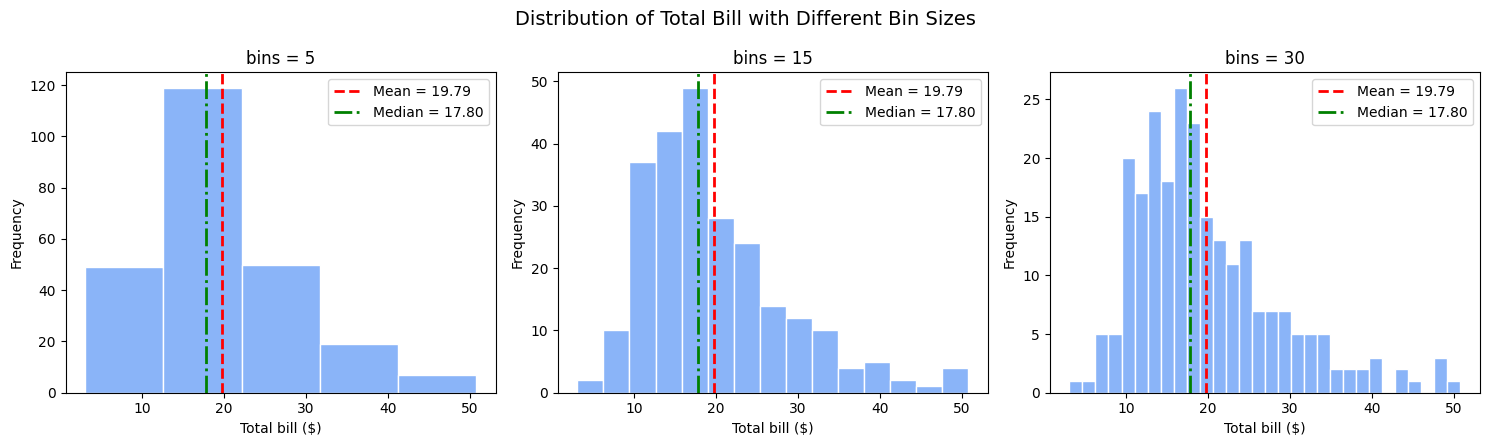

In [5]:
mean_v, median_v = tips["total_bill"].mean(), tips["total_bill"].median()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=False)
for ax, bins in zip(axes, [5, 15, 30]):
    ax.hist(tips["total_bill"], bins=bins, color="#8ab4f8", edgecolor="white")
    ax.axvline(mean_v, color="red", linestyle="--", linewidth=2, label=f"Mean = {mean_v:.2f}")
    ax.axvline(median_v, color="green", linestyle="-.", linewidth=2, label=f"Median = {median_v:.2f}")
    ax.set_title(f"bins = {bins}")
    ax.set_xlabel("Total bill ($)")
    ax.set_ylabel("Frequency")
    ax.legend()
fig.suptitle("Distribution of Total Bill with Different Bin Sizes", fontsize=14)
plt.tight_layout()
plt.show()

**Insight:** The distribution is right-skewed: most bills fall between \$10 and \$25, with a long tail of expensive bills. The mean (about \$19.79) sits above the median (\$17.80) because those large bills pull it up. Too few bins hide the shape, while too many make it noisy; 15 bins is a good middle ground.

## Task 5: Scatter plot (mpg)

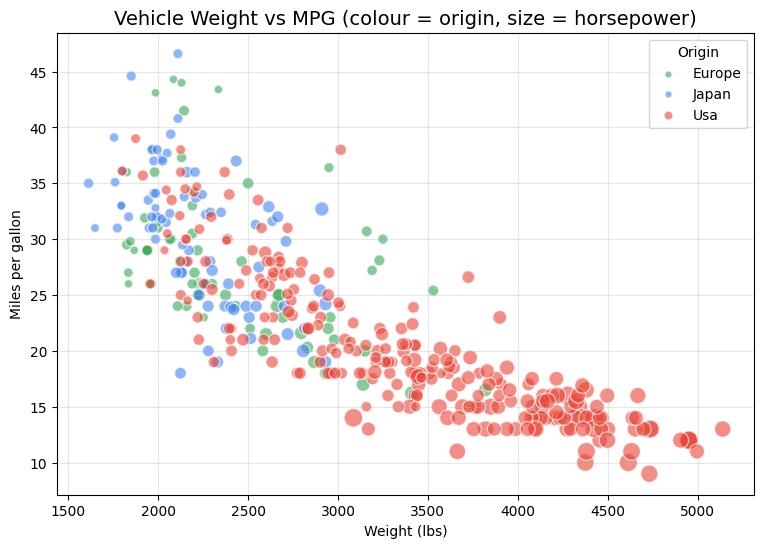

In [6]:
fig, ax = plt.subplots(figsize=(9, 6))
palette = {"usa": "#EA4335", "japan": "#4285F4", "europe": "#34A853"}
for origin, grp in mpg.dropna(subset=["horsepower"]).groupby("origin"):
    ax.scatter(grp["weight"], grp["mpg"], s=grp["horsepower"] * 0.8, alpha=0.6,
               color=palette[origin], label=origin.title(), edgecolor="white")
ax.set_title("Vehicle Weight vs MPG (colour = origin, size = horsepower)", fontsize=14)
ax.set_xlabel("Weight (lbs)")
ax.set_ylabel("Miles per gallon")
leg = ax.legend(title="Origin", markerscale=0.6)
ax.grid(True, alpha=0.3)
plt.show()

**Insight:** There is a clear negative relationship: heavier cars get fewer miles per gallon. Big, high-horsepower cars (large bubbles) are mostly American and sit at the heavy, low-mpg end, while Japanese and European cars cluster among the lighter, more efficient ones.

## Task 6: Pie / donut chart (tips)

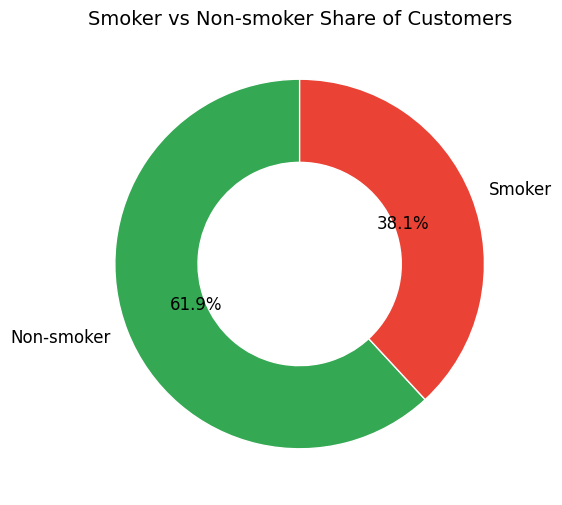

In [7]:
smoker_counts = tips["smoker"].value_counts()

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(smoker_counts.values, labels=["Non-smoker" if s == "No" else "Smoker" for s in smoker_counts.index],
       autopct="%1.1f%%", startangle=90, colors=["#34A853", "#EA4335"],
       wedgeprops=dict(width=0.45, edgecolor="white"), textprops={"fontsize": 12})
ax.set_title("Smoker vs Non-smoker Share of Customers", fontsize=14)
plt.show()

**Insight:** Non-smokers make up about 61.9% of the parties (151 of 244) and smokers about 38.1% (93 of 244). Non-smoking customers are the clear majority.

## Task 7: Mini dashboard (2 x 2 subplots, saved as PNG at 300 dpi)

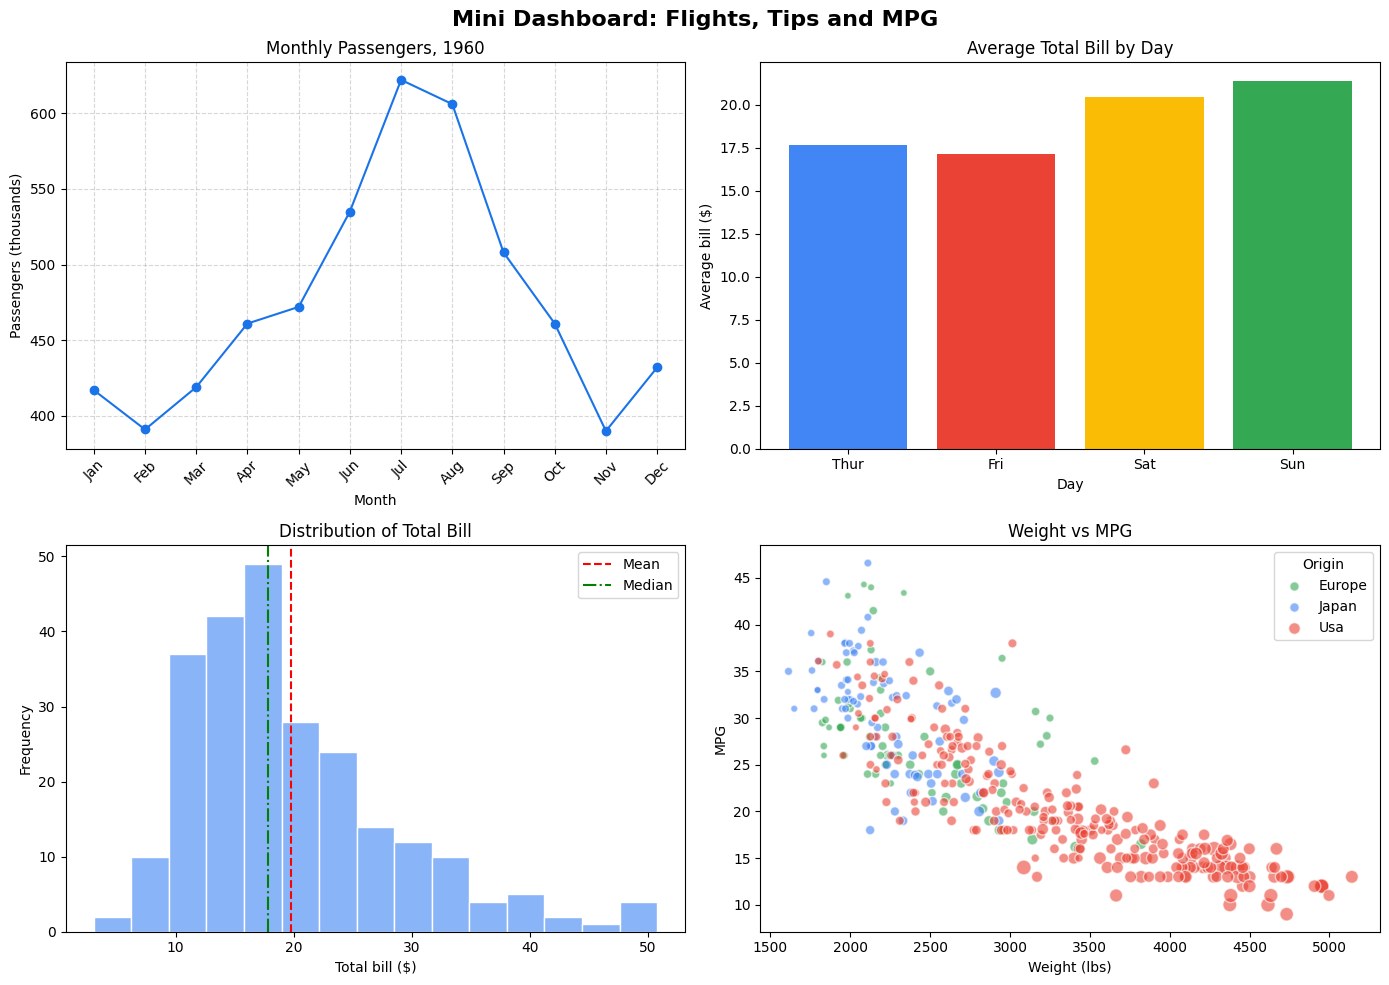

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# (0,0) Line plot
axes[0, 0].plot(f1960["month"].astype(str), f1960["passengers"], marker="o", color="#1a73e8")
axes[0, 0].set_title("Monthly Passengers, 1960")
axes[0, 0].set_xlabel("Month"); axes[0, 0].set_ylabel("Passengers (thousands)")
axes[0, 0].tick_params(axis="x", rotation=45); axes[0, 0].grid(True, linestyle="--", alpha=0.5)

# (0,1) Bar chart
axes[0, 1].bar(avg_day.index.astype(str), avg_day.values, color=colors)
axes[0, 1].set_title("Average Total Bill by Day")
axes[0, 1].set_xlabel("Day"); axes[0, 1].set_ylabel("Average bill ($)")

# (1,0) Histogram
axes[1, 0].hist(tips["total_bill"], bins=15, color="#8ab4f8", edgecolor="white")
axes[1, 0].axvline(mean_v, color="red", linestyle="--", label="Mean")
axes[1, 0].axvline(median_v, color="green", linestyle="-.", label="Median")
axes[1, 0].set_title("Distribution of Total Bill")
axes[1, 0].set_xlabel("Total bill ($)"); axes[1, 0].set_ylabel("Frequency"); axes[1, 0].legend()

# (1,1) Scatter
for origin, grp in mpg.dropna(subset=["horsepower"]).groupby("origin"):
    axes[1, 1].scatter(grp["weight"], grp["mpg"], s=grp["horsepower"] * 0.5, alpha=0.6,
                       color=palette[origin], label=origin.title(), edgecolor="white")
axes[1, 1].set_title("Weight vs MPG")
axes[1, 1].set_xlabel("Weight (lbs)"); axes[1, 1].set_ylabel("MPG"); axes[1, 1].legend(title="Origin")

fig.suptitle("Mini Dashboard: Flights, Tips and MPG", fontsize=16, fontweight="bold")
plt.tight_layout()
fig.savefig("mini_dashboard.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight:** Together the four views show seasonality in air travel (summer peak), higher spending on weekends, right-skewed restaurant bills, and a strong weight-mpg trade-off in cars. The dashboard was saved as `mini_dashboard.png` at 300 dpi.

# Part 2: Seaborn Tasks

## Task 1: Countplot (titanic)

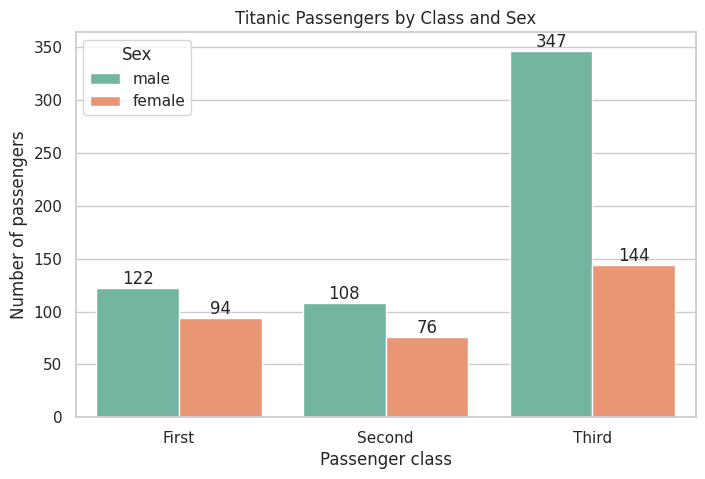

In [9]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=titanic, x="class", hue="sex", palette="Set2")
for c in ax.containers:
    ax.bar_label(c)
plt.title("Titanic Passengers by Class and Sex")
plt.xlabel("Passenger class")
plt.ylabel("Number of passengers")
plt.legend(title="Sex")
plt.show()

**Insight:** Third class is the largest group, driven by a big number of men (347 vs 144 women). First and second class are much more balanced between sexes.

## Task 2: Histogram with KDE (penguins)

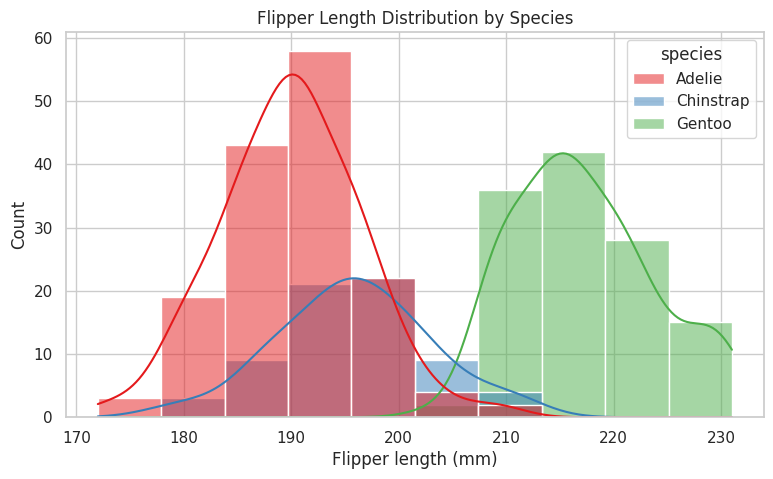

In [10]:
plt.figure(figsize=(9, 5))
sns.histplot(data=penguins, x="flipper_length_mm", hue="species", kde=True, palette="Set1", alpha=0.5)
plt.title("Flipper Length Distribution by Species")
plt.xlabel("Flipper length (mm)")
plt.ylabel("Count")
plt.show()

**Insight:** Gentoo penguins have clearly longer flippers (mean about 217 mm) than Adelie (about 190 mm) and Chinstrap (about 196 mm). Adelie and Chinstrap overlap considerably, so flipper length separates Gentoo easily but not the other two.

## Task 3: Box vs violin (penguins)

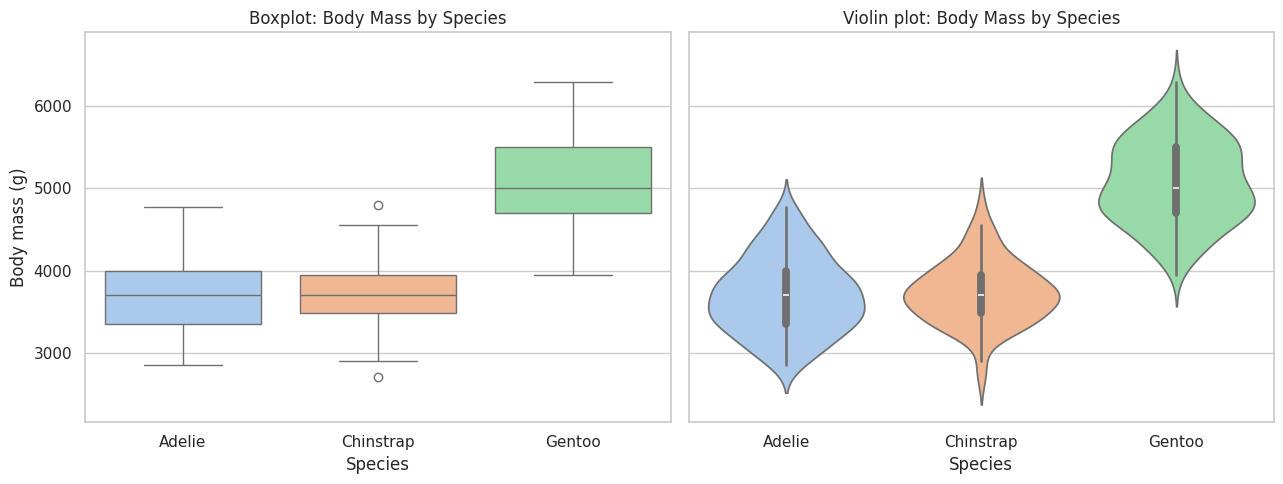

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
sns.boxplot(data=penguins, x="species", y="body_mass_g", hue="species", palette="pastel", legend=False, ax=axes[0])
axes[0].set_title("Boxplot: Body Mass by Species")
axes[0].set_xlabel("Species"); axes[0].set_ylabel("Body mass (g)")

sns.violinplot(data=penguins, x="species", y="body_mass_g", hue="species", palette="pastel", legend=False, ax=axes[1])
axes[1].set_title("Violin plot: Body Mass by Species")
axes[1].set_xlabel("Species"); axes[1].set_ylabel("Body mass (g)")
plt.tight_layout()
plt.show()

**Insight:** Gentoo penguins are the heaviest (median near 5,000 g), while Adelie and Chinstrap are similar at about 3,700 g.

**Box vs violin:** The boxplot summarises median, quartiles and outliers compactly. The violin plot shows more because it also reveals the full shape of the distribution (spread, skew and multiple peaks), which a box hides.

## Task 4: Scatterplot (penguins)

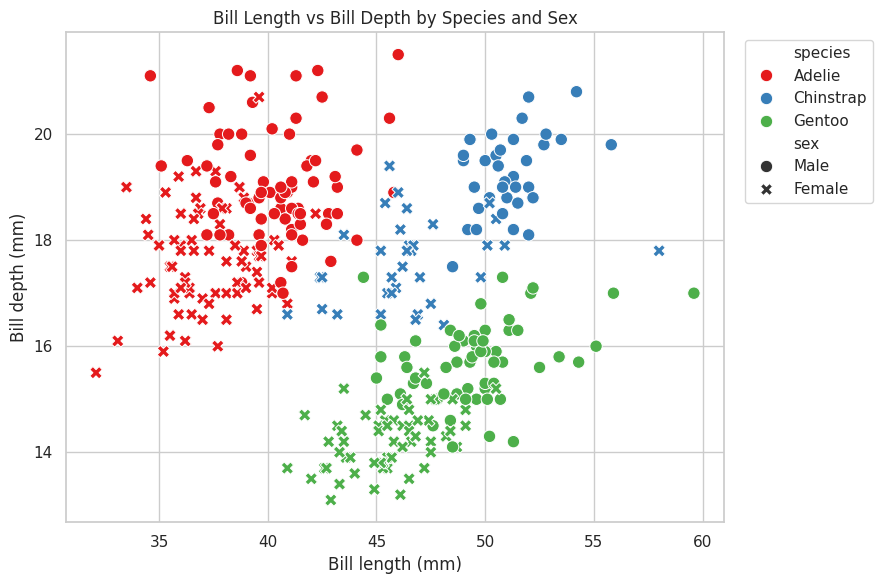

In [12]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=penguins, x="bill_length_mm", y="bill_depth_mm", hue="species", style="sex", s=80, palette="Set1")
plt.title("Bill Length vs Bill Depth by Species and Sex")
plt.xlabel("Bill length (mm)")
plt.ylabel("Bill depth (mm)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Insight:** Species form three fairly distinct clusters: Adelie have short, deep bills, Gentoo have long, shallow bills, and Chinstrap have long, deep bills. Within each species males sit slightly higher and to the right, meaning their bills are somewhat larger.

## Task 5: Heatmap (penguins)

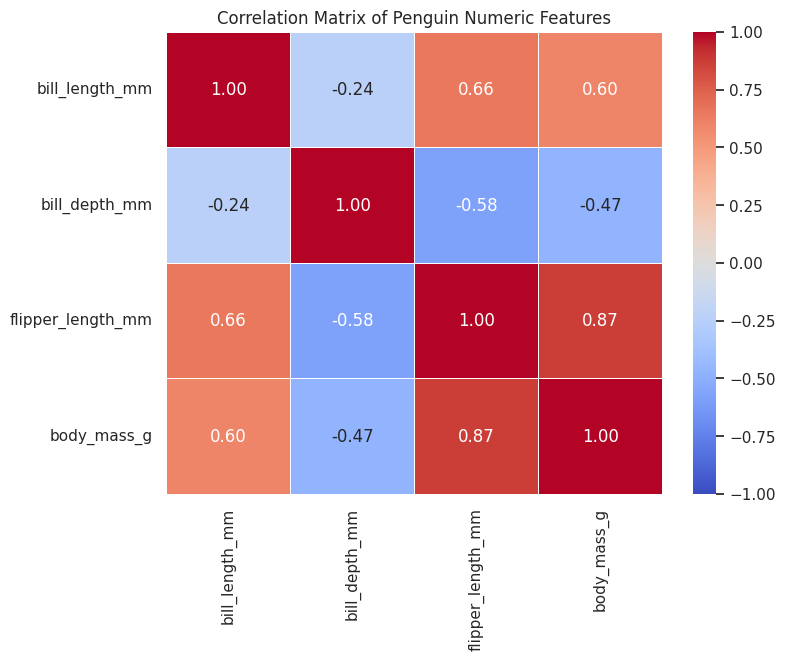

In [13]:
corr = penguins.select_dtypes(include="number").corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation Matrix of Penguin Numeric Features")
plt.show()

**Insight:** Flipper length and body mass are strongly positively correlated (about 0.87). Bill depth is negatively correlated with the other features, notably with flipper length (about -0.58) and body mass (about -0.47). This negative sign is partly a species-mixing effect, which the pairplot below helps explain.

## Task 6: Pairplot (penguins)

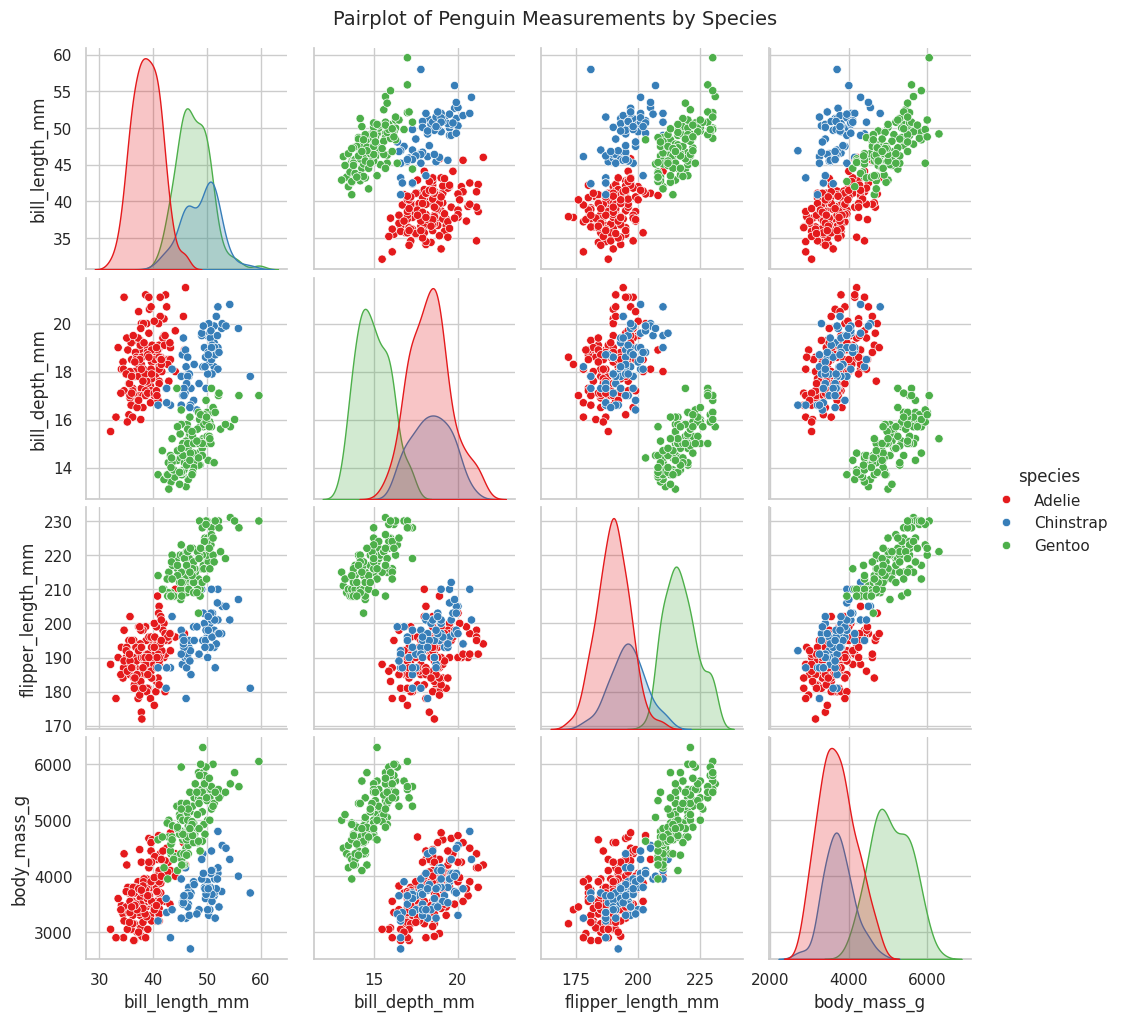

In [14]:
g = sns.pairplot(penguins, hue="species", palette="Set1", corner=False)
g.figure.suptitle("Pairplot of Penguin Measurements by Species", y=1.02, fontsize=14)
plt.show()

**3 insights:**
1. Gentoo penguins stand out on almost every pairing, with the longest flippers and highest body mass, so they are easy to separate from the other two species.
2. Adelie and Chinstrap overlap heavily on flipper length and body mass, but separate well on bill length (Chinstrap are longer).
3. The overall negative link between bill depth and flipper length reverses inside each species (positive within Adelie, Chinstrap and Gentoo). The negative overall trend comes from mixing species, a case of Simpson's paradox.

## Task 7: lmplot / FacetGrid (tips)

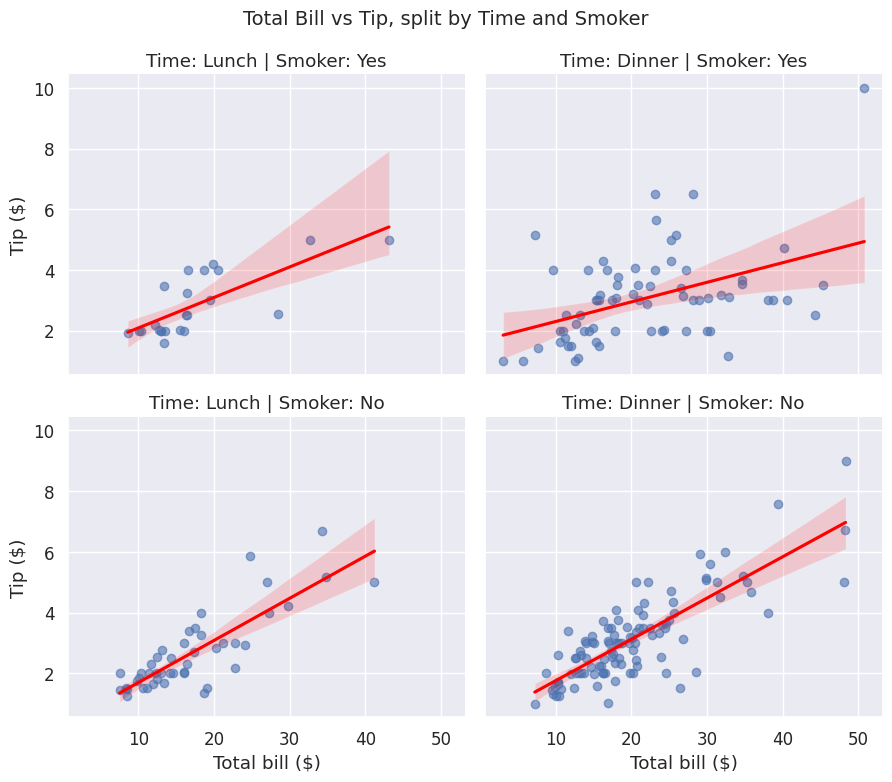

In [15]:
sns.set_theme(style="darkgrid", palette="deep", font_scale=1.1)

g = sns.lmplot(data=tips, x="total_bill", y="tip", col="time", row="smoker",
               height=3.8, aspect=1.2, line_kws={"color": "red"}, scatter_kws={"alpha": 0.6})
g.set_axis_labels("Total bill ($)", "Tip ($)")
g.set_titles("Time: {col_name} | Smoker: {row_name}")
g.figure.suptitle("Total Bill vs Tip, split by Time and Smoker", y=1.03, fontsize=14)
plt.show()

**Insight:** Tips rise with the bill in every panel, so a larger bill means a larger tip. The relationship is tightest for non-smokers (correlation about 0.8 at both lunch and dinner) and loosest for smokers at dinner (about 0.44), where tips vary a lot for the same bill. The smoker-lunch panel has only 23 points, so its line should be read with caution.